In [1]:
# Importing standard libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

In [2]:
import pandas as pd
import zipfile
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
import zipfile

zip_file = '/content/drive/MyDrive/מכללת איקום/Fruit_best.zip'  # הנתיב המעודכן לקובץ הדחוס בדרייב

with zipfile.ZipFile(zip_file, 'r') as zip_ref:
    zip_ref.extractall('/content/dataset')  # חילוץ הקבצים לתיקייה חדשה


In [14]:
import os
import shutil

# מחיקת התיקיות הישנות במידה והן קיימות כדי להבטיח שאיננו משתמשים במידע ישן משוכפל
for folder in ['/content/dataset/Fruit', '/content/dataset/__MACOSX']:
    if os.path.exists(folder):
        shutil.rmtree(folder)

# בדיקת מבנה התיקיות שחולצו מתוך הזיפ החדש
print("Files in /content/dataset:", os.listdir('/content/dataset'))


Files in /content/dataset: ['Fruit_best']


In [15]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import json
import os

# הגדרת נתיבים מדויקים בהתאם למבנה של Fruit_best.zip (אותיות גדולות Train ו-Test)
TRAIN_DIR = '/content/dataset/Train'
TEST_DIR  = '/content/dataset/Test'
IMG_SIZE  = (100, 100)
BATCH     = 32

# בדיקת קיום התיקיות עם שמות מעודכנים
if not os.path.exists(TRAIN_DIR):
    # תמיכה במקרה והתיקייה היא Fruit_best או מבנה פנימי אחר
    possible_base = '/content/dataset'
    if 'Fruit_best' in os.listdir(possible_base):
        possible_base = os.path.join(possible_base, 'Fruit_best')
    TRAIN_DIR = os.path.join(possible_base, 'Train')
    TEST_DIR = os.path.join(possible_base, 'Test')

print(f"Using actual train path: {TRAIN_DIR}")
print(f"Using actual test path: {TEST_DIR}")

# הגדרת האוגמנטציה לאימון
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    zoom_range=0.2,
    horizontal_flip=True,
    brightness_range=[0.8, 1.2],
    validation_split=0.2
)

val_datagen  = ImageDataGenerator(rescale=1./255, validation_split=0.2)
test_datagen = ImageDataGenerator(rescale=1./255)

training_set = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH,
    class_mode='categorical',
    subset='training',
    seed=42
)

validation_set = val_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH,
    class_mode='categorical',
    subset='validation',
    shuffle=False,
    seed=42
)

test_set = test_datagen.flow_from_directory(
    TEST_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH,
    class_mode='categorical',
    shuffle=False
)

# שמירת סדר הקטגוריות החדש
class_names = list(training_set.class_indices.keys())
print("Detected classes:", class_names)
with open('/content/class_names_v2.json', 'w') as f:
    json.dump(class_names, f)


Using actual train path: /content/dataset/Fruit_best/Train
Using actual test path: /content/dataset/Fruit_best/Test
Found 8280 images belonging to 5 classes.
Found 2069 images belonging to 5 classes.
Found 3355 images belonging to 5 classes.
Detected classes: ['Apple', 'Avocado', 'Banana', 'Eggplant', 'Tomato']


In [5]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Training data generator with augmentation
train_datagen = ImageDataGenerator(
    rescale=1./255,         # Normalize pixel values to [0,1] — helps speed up training and stabilize gradients
    shear_range=0.2,        # Apply a slight diagonal transformation (shear) — simulates natural changes in camera angle
    zoom_range=0.2,         # Apply random zoom-in effect — helps the model recognize objects at different scales
    horizontal_flip=True    # Flip images horizontally — helps the model handle symmetry (e.g., cat facing left or right)
)

# Testing data generator — only normalization, no augmentation
test_datagen = ImageDataGenerator(rescale=1./255)

In [6]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import json
import os

# בדיקה היכן התיקיות נמצאות באמת לאחר החילוץ
if os.path.exists('/content/dataset/Fruit'):
    base_dir = '/content/dataset/Fruit'
elif os.path.exists('/content/dataset'):
    base_dir = '/content/dataset'
else:
    base_dir = '/content/Fruit'

TRAIN_DIR = os.path.join(base_dir, 'train')
TEST_DIR  = os.path.join(base_dir, 'test')
IMG_SIZE  = (100, 100)   # הגודל המקורי של התמונות – לא מאבדים פרטים
BATCH     = 32

print(f"Using train path: {TRAIN_DIR}")
print(f"Using test path: {TEST_DIR}")

# train: נרמול + augmentation, ו-20% נשמרים בצד ל-validation
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    zoom_range=0.2,
    horizontal_flip=True,
    brightness_range=[0.8, 1.2],
    validation_split=0.2
)

# validation + test: רק נרמול, בלי augmentation
val_datagen  = ImageDataGenerator(rescale=1./255, validation_split=0.2)
test_datagen = ImageDataGenerator(rescale=1./255)

training_set = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH,
    class_mode='categorical',
    subset='training',
    seed=42
)

validation_set = val_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH,
    class_mode='categorical',
    subset='validation',
    shuffle=False,
    seed=42
)

test_set = test_datagen.flow_from_directory(
    TEST_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH,
    class_mode='categorical',
    shuffle=False               # חשוב ל-confusion matrix בסוף
)

# בדיקה + שמירת סדר הקטגוריות לאפליקציה
print(training_set.class_indices)
class_names = list(training_set.class_indices.keys())
with open('/content/class_names.json', 'w') as f:
    json.dump(class_names, f)

Using train path: /content/dataset/Fruit/train
Using test path: /content/dataset/Fruit/test
Found 5740 images belonging to 5 classes.
Found 1432 images belonging to 5 classes.
Found 2388 images belonging to 5 classes.
{'Apple': 0, 'Avocado': 1, 'Banana': 2, 'Eggplant': 3, 'Tomato': 4}


In [16]:
from keras.models import Sequential
from keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
import os

cnn = Sequential()

# שכבת קונבולוציה ראשונה
cnn.add(Conv2D(filters=32, kernel_size=3, activation='relu', input_shape=[100, 100, 3]))
cnn.add(MaxPooling2D(pool_size=2, strides=2))

# שכבת קונבולוציה שנייה
cnn.add(Conv2D(filters=32, kernel_size=3, activation='relu'))
cnn.add(MaxPooling2D(pool_size=2, strides=2))

# Flatten
cnn.add(Flatten())

# Fully Connected
cnn.add(Dense(units=128, activation='relu'))

# שכבת פלט – 5 פירות
cnn.add(Dense(units=5, activation='softmax'))

cnn.summary()

# קומפילציה
cnn.compile(optimizer='adam',
            loss='categorical_crossentropy',
            metrics=['accuracy'])

# אימון על הסט המעודכן באמת מתוך Fruit_best
history = cnn.fit(
    training_set,
    validation_data=validation_set,
    epochs=10
)

# הערכה על סט הבדיקה החדש שמכיל 3,355 תמונות מגוונות
test_loss, test_acc = cnn.evaluate(test_set)
print(f"Test accuracy on Fruit_best dataset: {test_acc:.2%}")

# שמירה מסודרת לדרייב לתיקייה vision-project
os.makedirs('/content/drive/MyDrive/vision-project', exist_ok=True)
cnn.save('/content/drive/MyDrive/vision-project/model_v2.keras')
!cp /content/class_names_v2.json /content/drive/MyDrive/vision-project/class_names_v2.json

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 98, 98, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 49, 49, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 47, 47, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 23, 23, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 16928)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     2,166,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,177,701 (8.31 MB)

 Trainable params: 2,177,701 (8.31 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
259/259 ━━━━━━━━━━━━━━━━━━━━ 160s 607ms/step - accuracy: 0.8815 - loss: 0.2984 - val_accuracy: 0.8468 - val_loss: 1.1824
Epoch 2/10
259/259 ━━━━━━━━━━━━━━━━━━━━ 157s 605ms/step - accuracy: 0.9685 - loss: 0.0863 - val_accuracy: 0.8014 - val_loss: 1.9349
Epoch 3/10
259/259 ━━━━━━━━━━━━━━━━━━━━ 157s 606ms/step - accuracy: 0.9874 - loss: 0.0388 - val_accuracy: 0.8062 - val_loss: 1.9774
Epoch 4/10
259/259 ━━━━━━━━━━━━━━━━━━━━ 201s 601ms/step - accuracy: 0.9913 - loss: 0.0263 - val_accuracy: 0.7927 - val_loss: 2.3292
Epoch 5/10
259/259 ━━━━━━━━━━━━━━━━━━━━ 156s 603ms/step - accuracy: 0.9919 - loss: 0.0228 - val_accuracy: 0.7825 - val_loss: 3.2721
Epoch 6/10
259/259 ━━━━━━━━━━━━━━━━━━━━ 203s 609ms/step - accuracy: 0.9967 - loss: 0.0089 - val_accuracy: 0.8328 - val_loss: 3.2874
Epoch 7/10
259/259 ━━━━━━━━━━━━━━━━━━━━ 156s 603ms/step - accuracy: 0.9867 - loss: 0.0400 - val_accuracy: 0.7801 - val_loss: 2.8316
Epoch 8/10
259/259 ━━━━━━━━━━━━━━━━━━━━ 157s 605ms/step - accuracy: 0.9977 -

In [17]:
from tensorflow.keras.models import load_model
import os

# יצירת התיקייה בדרייב במידה ואינה קיימת כדי למנוע שגיאת FileNotFoundError
os.makedirs('/content/drive/MyDrive/vision-project', exist_ok=True)

# 1. שמירת המודל המאומן עם שם ייחודי חדש
cnn.save('/content/drive/MyDrive/vision-project/model_v2.keras')

# 2. טעינה מחדש לבדיקה
model = load_model('/content/drive/MyDrive/vision-project/model_v2.keras')

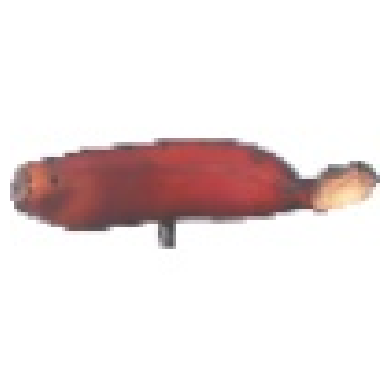

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step
Apple        0.04%
Avocado      0.00%
Banana      99.96%
Eggplant     0.00%
Tomato       0.00%

Predicted Class: Banana (99.96%)


In [18]:
import numpy as np
import json
import os
import matplotlib.pyplot as plt
from keras.preprocessing import image

# טעינת סדר הקטגוריות מהקובץ המקורי התקין
with open('/content/class_names.json') as f:
    class_names = json.load(f)

# חיפוש תמונות בצורה רקורסיבית (גם בתוך תת-תיקיות)
banana_dir = os.path.join(TEST_DIR, 'Banana')
valid_images = []

for root, dirs, files in os.walk(banana_dir):
    for f in files:
        if f.lower().endswith(('.png', '.jpg', '.jpeg')):
            valid_images.append(os.path.join(root, f))

if len(valid_images) > 0:
    img_path = valid_images[0] # לוקחים את התמונה הראשונה שנמצאה

    # טעינה בגודל שהמודל מצפה לו
    test_image = image.load_img(img_path, target_size=(100, 100))

    plt.imshow(test_image)
    plt.axis('off')
    plt.show()

    # אותו עיבוד מקדים כמו באימון
    test_image = image.img_to_array(test_image) / 255.0
    test_image = np.expand_dims(test_image, axis=0)

    # חיזוי
    result = model.predict(test_image)[0]

    # הדפסת כל ההסתברויות
    for name, prob in zip(class_names, result):
        print(f"{name:10s} {prob*100:6.2f}%")

    # הקטגוריה עם ההסתברות הגבוהה ביותר
    idx = np.argmax(result)
    confidence = result[idx]

    print(f"\nPredicted Class: {class_names[idx]} ({confidence*100:.2f}%)")
else:
    print("לא נמצאו קבצי תמונות בתיקיית הבננות.")

אמיתי: Apple


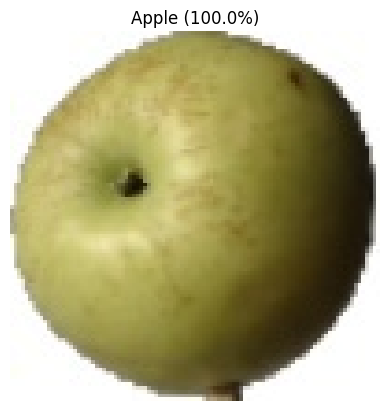

אמיתי: Avocado


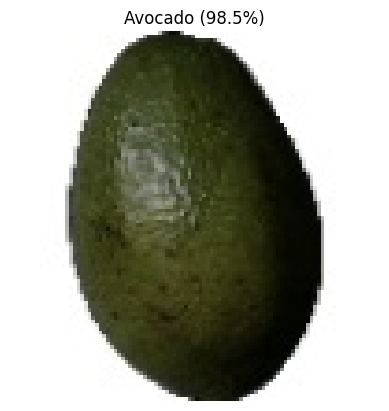

אמיתי: Banana


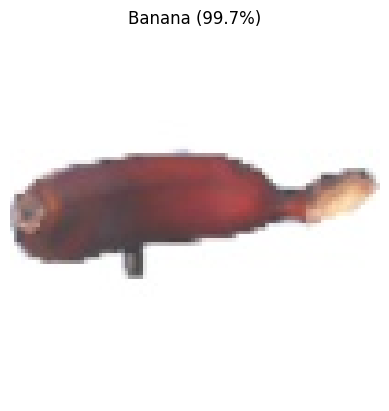

אמיתי: Eggplant


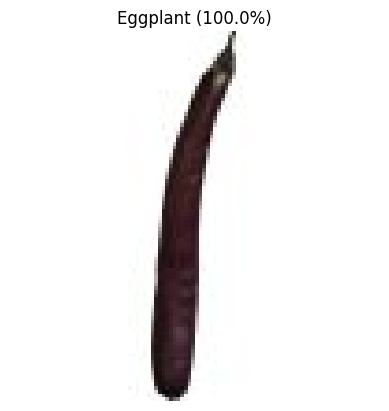

אמיתי: Tomato


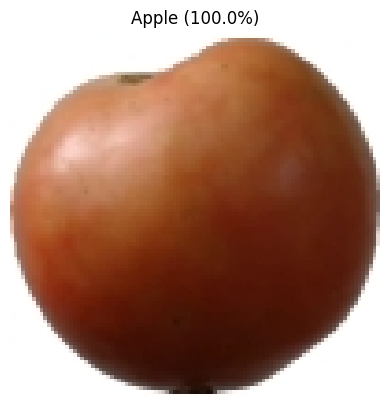

In [19]:
import numpy as np, json, os, random
import matplotlib.pyplot as plt
from keras.preprocessing import image

with open('/content/class_names.json') as f:
    class_names = json.load(f)

def predict_image(img_path):
    img = image.load_img(img_path, target_size=(100, 100))
    arr = np.expand_dims(image.img_to_array(img) / 255.0, axis=0)
    result = model.predict(arr, verbose=0)[0]

    idx = np.argmax(result)
    conf = result[idx]
    label = class_names[idx] if conf >= 0.6 else 'unknown'

    plt.imshow(img); plt.axis('off')
    plt.title(f"{label} ({conf*100:.1f}%)")
    plt.show()
    return label, conf

# תמונה אקראית אחת מכל פרי ב-test (חיפוש רקורסיבי תחת תיקיית כל פרי)
for fruit in class_names:
    folder = os.path.join(TEST_DIR, fruit)
    if os.path.exists(folder):
        valid_images = []
        for root, dirs, files in os.walk(folder):
            for f in files:
                if f.lower().endswith(('.png', '.jpg', '.jpeg')):
                    valid_images.append(os.path.join(root, f))

        if valid_images:
            f = random.choice(valid_images)
            print(f"אמיתי: {fruit}")
            predict_image(f)
        else:
            print(f"לא נמצאו תמונות תקינות בתיקייה {fruit}")
    else:
        print(f"התיקייה {fruit} לא נמצאה בנתיב ה-Test")